In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

In [47]:
df = pd.read_csv("data.csv", header=None)

columns = [
    "ID", "Diagnosis",
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean",
    "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst", "area_worst",
    "smoothness_worst", "compactness_worst", "concavity_worst",
    "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"
]

df.columns = columns
df["Diagnosis"] = df["Diagnosis"].map({"M": 1, "B": 0})

X = df.drop(columns=["ID", "Diagnosis"])
y = df["Diagnosis"]

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [34]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

prediction = model.predict(X_test)
accuracy_before = accuracy_score(y_test, prediction)

#print("Features before PCA:", X_train.shape[1])
print("Accuracy before PCA:", round(accuracy_before * 100, 2), "%")

Accuracy before PCA: 96.49 %


In [26]:
pca = PCA(n_components=5)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Features before PCA:", X_train.shape[1])
print("Features after PCA:", X_train_pca.shape[1])

Features before PCA: 30
Features after PCA: 5


In [40]:
model_after = LogisticRegression(max_iter=1000)
model_after.fit(X_train_pca, y_train)

prediction = model_after.predict(X_test_pca)
accuracy_after = accuracy_score(y_test, prediction)

print("Accuracy after PCA:", round(accuracy_after * 100, 2), "%")
print("Accuracy after PCA:", accuracy_after*100)

Accuracy after PCA: 97.37 %
Accuracy after PCA: 97.36842105263158


In [28]:
print("Accuracy comparison:")
print("Before PCA:", round(accuracy_before * 100, 2), "%")
print("After PCA:", round(accuracy_after * 100, 2), "%")

Accuracy comparison:
Before PCA: 96.49 %
After PCA: 97.37 %


In [33]:
variance = pca.explained_variance_ratio_

print(variance * 100)
print("Total variance:", sum(variance) * 100)

[44.5935222  18.54525545  9.58464121  6.59376825  5.62228616]
Total variance: 84.93947327275534


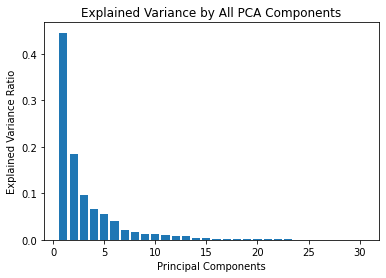

In [45]:
pca_all = PCA()
pca_all.fit(X_train)
var=pca_all.explained_variance_ratio_

plt.bar(range(1, 31), var)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by All PCA Components")
plt.show()

### Explanation of the graphs

1. **Explained Variance of Five Principal Components:** Each bar shows how much information (variance) is captured by one of the five selected principal components. Taller bars represent components that retain more information.

2. **Data Using the First Two Principal Components:** Each dot represents one sample in the dataset. The horizontal and vertical axes show its values on PCA1 and PCA2. The colours represent the two diagnosis classes (benign and malignant). This graph helps us see how the classes are distributed after dimensionality reduction.

3. **Explained Variance by All PCA Components:** Each bar shows the proportion of information captured by each of the original 30 possible principal components. It helps show how much information is captured by the early components compared with later ones.